# 01 — Exploratory Data Analysis: Telco Customer Churn

**Goal:** understand the data quality, the target distribution and how churn relates to customer
attributes, so that the preprocessing and modelling decisions are evidence-based.

> All relationships shown here are **associations in historical data**, not causal effects.
> Figures are saved to `reports/figures/` with the prefix `eda_`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config
from src.data_preprocessing import load_raw_data, clean_data
from src.plotting import apply_style, CHURN_COLORS, ORANGE, GRAY, TEXT_SECONDARY

%matplotlib inline
apply_style()
FIG_DIR = config.FIGURES_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

def save(fig, name):
    fig.savefig(FIG_DIR / name)

## 1. Data inspection

In [2]:
raw = load_raw_data()
print(f"Customers: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

18:20:42 | INFO    | src.data_preprocessing | Loaded 7043 rows x 21 columns from WA_Fn-UseC_-Telco-Customer-Churn.csv


Customers: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_null": raw.isna().sum(),
    "example": raw.iloc[0],
})
summary

,dtype,n_unique,n_null,example
customerID,str,7043,0,7590-VHVEG
gender,str,2,0,Female
SeniorCitizen,int64,2,0,0
Partner,str,2,0,Yes
Dependents,str,2,0,No
tenure,int64,73,0,1
PhoneService,str,2,0,No
MultipleLines,str,3,0,No phone service
InternetService,str,3,0,DSL
OnlineSecurity,str,3,0,No


In [4]:
print("Duplicated rows:          ", raw.duplicated().sum())
print("Duplicated customer IDs:  ", raw[config.ID_COL].duplicated().sum())
print("Duplicated rows ignoring ID:", raw.drop(columns=config.ID_COL).duplicated().sum())

Duplicated rows:           0
Duplicated customer IDs:   0
Duplicated rows ignoring ID: 22


### 1.1 Inconsistent values: `TotalCharges`

`TotalCharges` is stored as **text**. Let's find the values that cannot be parsed as numbers.

In [5]:
total_numeric = pd.to_numeric(raw["TotalCharges"], errors="coerce")
bad = raw.loc[total_numeric.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
print(f"Non-numeric TotalCharges: {len(bad)}")
print("Raw values:", sorted(set(map(repr, bad["TotalCharges"]))))
print("Tenure of those customers:", bad["tenure"].unique())
print("Customers with tenure == 0 in the whole dataset:", (raw["tenure"] == 0).sum())
bad

Non-numeric TotalCharges: 11
Raw values: ["' '"]
Tenure of those customers: [0]
Customers with tenure == 0 in the whole dataset: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Cleaning decision:** every blank `TotalCharges` belongs to a customer with `tenure == 0`
(and all `tenure == 0` customers have a blank value). These are brand-new customers who have not been
billed yet, so their accumulated charges are **0**. This is a deterministic business rule
(it learns nothing from the data), so it can be applied before the train/test split without leakage.
The pipeline additionally contains a median imputer as a safety net for unexpected nulls at inference time.

In [6]:
df = clean_data(raw)
print(df.dtypes.value_counts())
print("Nulls after cleaning:", int(df.isna().sum().sum()))

str        16
float64     4
int64       1
Name: count, dtype: int64
Nulls after cleaning: 0


### 1.2 Categorical levels

In [7]:
for col in config.CATEGORICAL_FEATURES:
    print(f"{col:<17} {sorted(df[col].unique())}")

gender            ['Female', 'Male']
Partner           ['No', 'Yes']
Dependents        ['No', 'Yes']
PhoneService      ['No', 'Yes']
MultipleLines     ['No', 'No phone service', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
OnlineSecurity    ['No', 'No internet service', 'Yes']
OnlineBackup      ['No', 'No internet service', 'Yes']
DeviceProtection  ['No', 'No internet service', 'Yes']
TechSupport       ['No', 'No internet service', 'Yes']
StreamingTV       ['No', 'No internet service', 'Yes']
StreamingMovies   ['No', 'No internet service', 'Yes']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['No', 'Yes']
PaymentMethod     ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


Several service columns contain the level `No internet service` / `No phone service`. They are
**structurally redundant** with `InternetService == "No"` / `PhoneService == "No"`, but they are
valid values (not errors), so they are kept as their own category for one-hot encoding.

## 2. Target variable: `Churn`

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn rate: 26.54%  |  Imbalance ratio (No:Yes) = 2.77 : 1


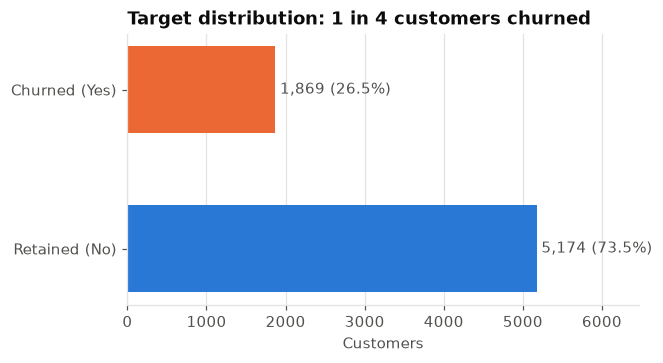

In [8]:
counts = df[config.TARGET_COL].value_counts().sort_index()
rate = df[config.TARGET_COL].mean()
print(counts.rename({0: "No", 1: "Yes"}))
print(f"Churn rate: {rate:.2%}  |  Imbalance ratio (No:Yes) = {counts[0] / counts[1]:.2f} : 1")

fig, ax = plt.subplots(figsize=(6, 3.2))
labels = ["Retained (No)", "Churned (Yes)"]
bars = ax.barh(labels, counts.values, color=[CHURN_COLORS["No"], CHURN_COLORS["Yes"]], height=0.55)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2,
            f"{n:,} ({n / counts.sum():.1%})", va="center", color=TEXT_SECONDARY)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Customers")
ax.set_title("Target distribution: 1 in 4 customers churned")
ax.grid(axis="y", visible=False)
save(fig, "eda_01_target_distribution.png")

The classes are **imbalanced (~73% / 27%)**. A model that always predicts "No churn" would reach
~73% accuracy while detecting zero churners, which is why accuracy alone is not an adequate metric
(see the Class Imbalance section of the README).

## 3. Numeric variables

In [9]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [10]:
# Outliers según la regla de Tukey (1.5 * IQR)
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.Series({c: iqr_outliers(df[c]) for c in num_cols}, name="IQR outliers")

tenure            0
MonthlyCharges    0
TotalCharges      0
Name: IQR outliers, dtype: int64

No numeric variable has values outside the Tukey fences, and ranges are plausible
(tenure 0–72 months, monthly charges ≈ 18–119). **No outlier treatment is needed.**
`TotalCharges` is strongly right-skewed because it accumulates over tenure.

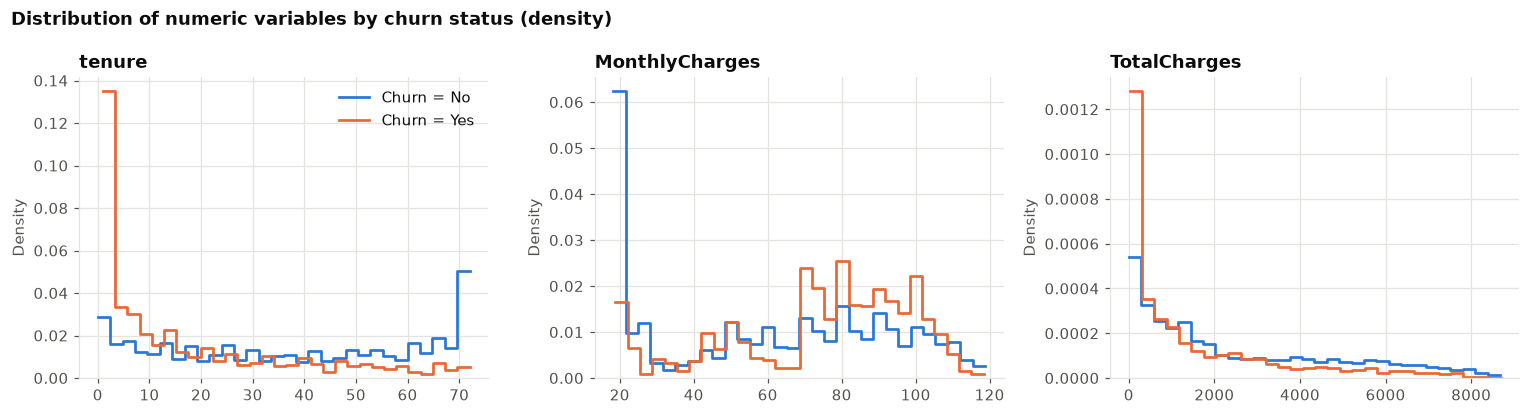

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, num_cols):
    for label, value in [("No", 0), ("Yes", 1)]:
        sns.histplot(df.loc[df.Churn == value, col], ax=ax, stat="density", bins=30,
                     color=CHURN_COLORS[label], element="step", fill=False, linewidth=1.8,
                     label=f"Churn = {label}")
    ax.set_title(col)
    ax.set_xlabel("")
axes[0].legend()
fig.suptitle("Distribution of numeric variables by churn status (density)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save(fig, "eda_02_numeric_distributions.png")

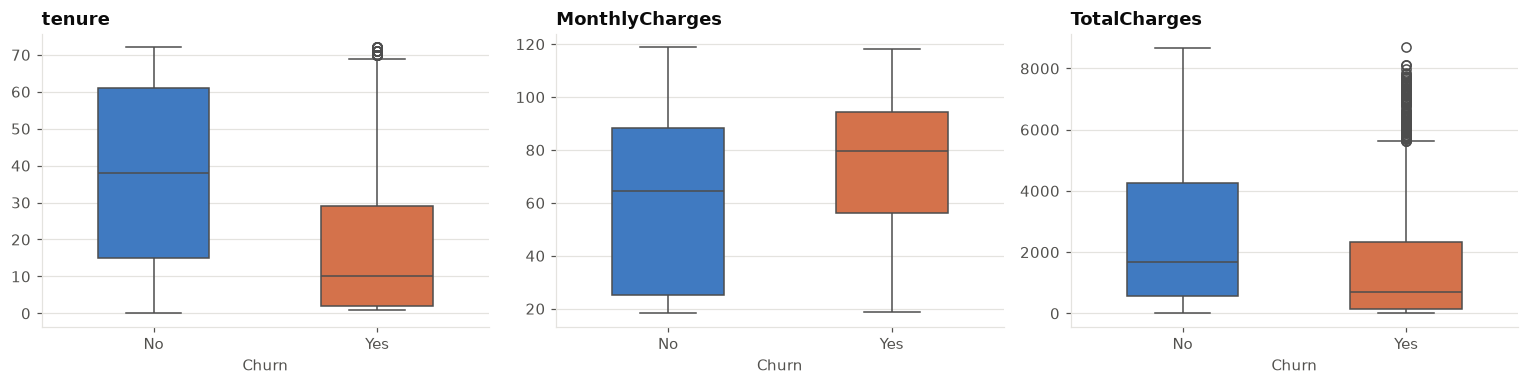

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
plot_df = df.assign(ChurnLabel=df.Churn.map({0: "No", 1: "Yes"}))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=plot_df, x="ChurnLabel", y=col, hue="ChurnLabel", palette=CHURN_COLORS,
                ax=ax, width=0.5, linewidth=1, legend=False, order=["No", "Yes"])
    ax.set_title(col)
    ax.set_xlabel("Churn")
    ax.set_ylabel("")
fig.tight_layout()
save(fig, "eda_03_numeric_boxplots.png")

In [13]:
# Test de Mann-Whitney U: ¿difieren las distribuciones entre churners y no churners?
rows = []
for col in num_cols:
    yes, no = df.loc[df.Churn == 1, col], df.loc[df.Churn == 0, col]
    u, p = stats.mannwhitneyu(yes, no)
    rows.append({"variable": col, "median_churn": yes.median(), "median_no_churn": no.median(),
                 "mann_whitney_p": p})
pd.DataFrame(rows)

,variable,median_churn,median_no_churn,mann_whitney_p
0,tenure,10.00,38.000,2.419636e-208
1,MonthlyCharges,79.65,64.425,3.311628e-54
2,TotalCharges,703.55,1679.525,5.685034e-83


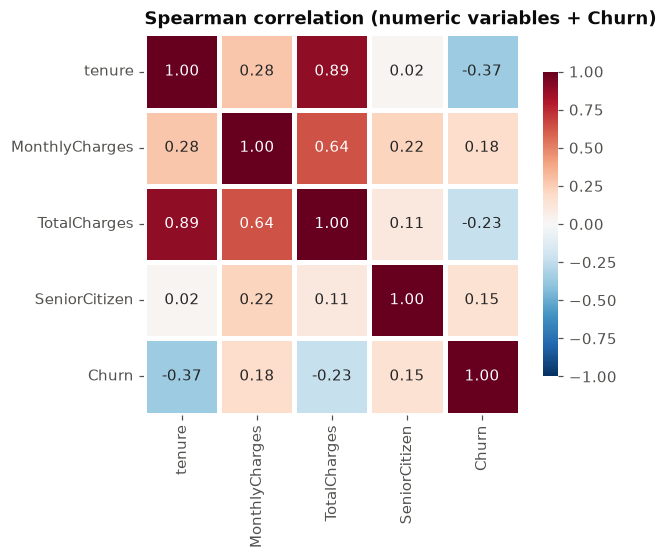

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlation (numeric variables + Churn)")
save(fig, "eda_06_correlation_heatmap.png")

`tenure` and `TotalCharges` are highly correlated (TotalCharges ≈ tenure × MonthlyCharges).
This collinearity does not hurt XGBoost and is controlled by L2 regularisation in the logistic
regression, but it does mean their individual coefficients/SHAP values **share credit** and should be
read together.

## 4. Churn rate by customer segment

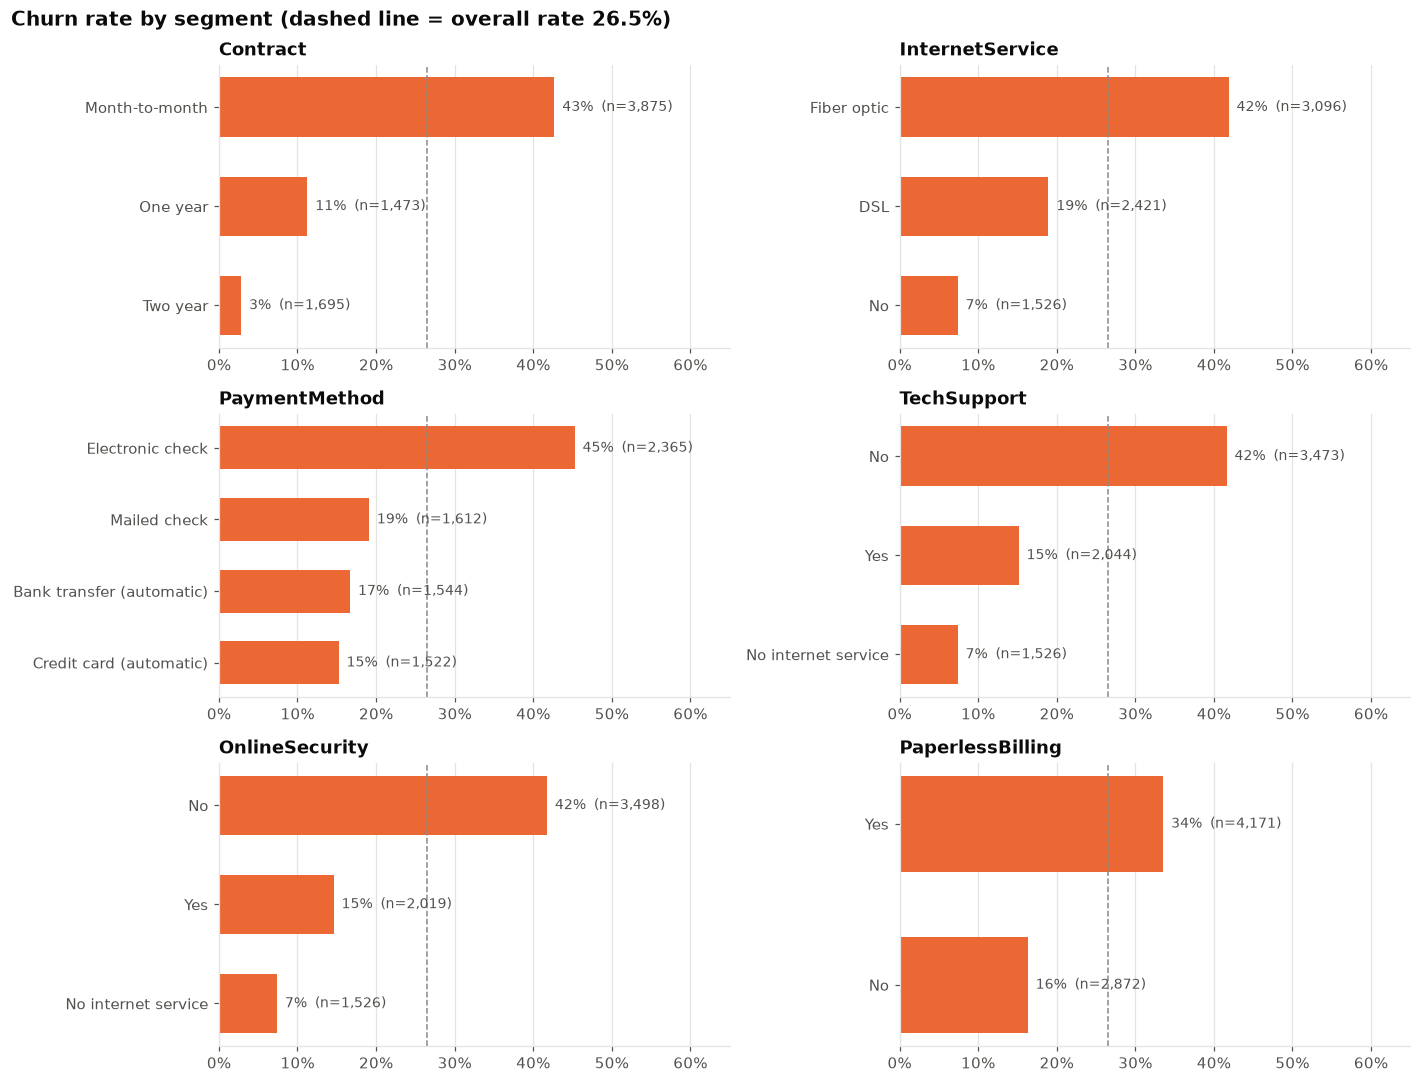

In [15]:
def churn_rate_table(col):
    t = df.groupby(col, observed=True)["Churn"].agg(customers="size", churn_rate="mean")
    return t.sort_values("churn_rate", ascending=False)

key_cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, col in zip(axes.ravel(), key_cats):
    t = churn_rate_table(col).sort_values("churn_rate")
    ax.barh(t.index.astype(str), t["churn_rate"], color=ORANGE, height=0.6)
    ax.axvline(rate, color=GRAY, linestyle="--", linewidth=1)
    for i, (r, n) in enumerate(zip(t["churn_rate"], t["customers"])):
        ax.text(r + 0.01, i, f"{r:.0%}  (n={n:,})", va="center", fontsize=9, color=TEXT_SECONDARY)
    ax.set_xlim(0, 0.65)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(col)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Churn rate by segment (dashed line = overall rate {rate:.1%})", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "eda_04_churn_rate_by_category.png")

In [16]:
# Asociación de todas las categóricas con Churn: chi-cuadrado y V de Cramér
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

assoc = pd.DataFrame(
    [(c, *cramers_v(df[c], df.Churn)) for c in config.CATEGORICAL_FEATURES + ["SeniorCitizen"]],
    columns=["variable", "cramers_v", "chi2_p_value"],
).sort_values("cramers_v", ascending=False).reset_index(drop=True)
assoc

,variable,cramers_v,chi2_p_value
0,Contract,0.410116,5.863038e-258
1,OnlineSecurity,0.347400,2.661150e-185
2,TechSupport,0.342916,1.443084e-180
3,InternetService,0.322455,9.571788e-160
4,PaymentMethod,0.303359,3.682355e-140
5,OnlineBackup,0.292316,2.079759e-131
6,DeviceProtection,0.281580,5.505219e-122
7,StreamingMovies,0.230951,2.667757e-82
8,StreamingTV,0.230502,5.528994e-82
9,PaperlessBilling,0.191498,4.073355e-58


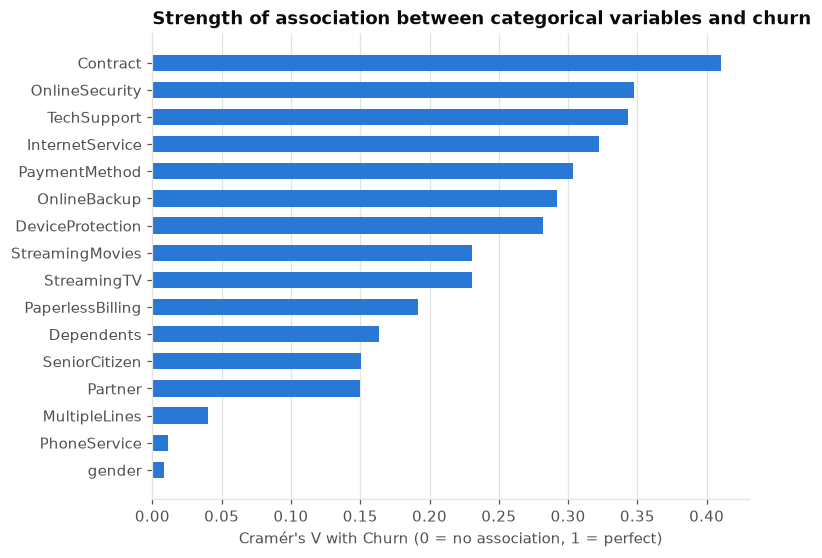

In [17]:
fig, ax = plt.subplots(figsize=(7, 5.5))
a = assoc.sort_values("cramers_v")
ax.barh(a["variable"], a["cramers_v"], color="#2a78d6", height=0.6)
ax.set_xlabel("Cramér's V with Churn (0 = no association, 1 = perfect)")
ax.set_title("Strength of association between categorical variables and churn")
ax.grid(axis="y", visible=False)
save(fig, "eda_07_cramers_v.png")

### 4.1 Tenure and charges bands

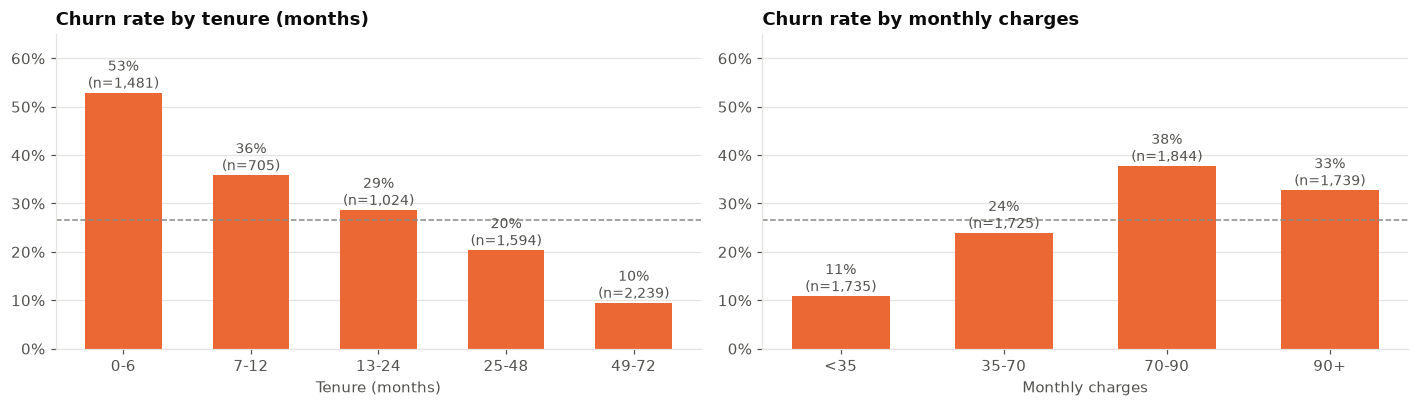

In [18]:
bands = df.assign(
    tenure_band=pd.cut(df.tenure, [-1, 6, 12, 24, 48, 72],
                       labels=["0-6", "7-12", "13-24", "25-48", "49-72"]),
    charges_band=pd.cut(df.MonthlyCharges, [0, 35, 70, 90, 120],
                        labels=["<35", "35-70", "70-90", "90+"]),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, title in [(axes[0], "tenure_band", "Tenure (months)"),
                       (axes[1], "charges_band", "Monthly charges")]:
    t = bands.groupby(col, observed=True)["Churn"].agg(customers="size", churn_rate="mean")
    ax.bar(t.index.astype(str), t["churn_rate"], color=ORANGE, width=0.6)
    ax.axhline(rate, color=GRAY, linestyle="--", linewidth=1)
    for i, (r, n) in enumerate(zip(t["churn_rate"], t["customers"])):
        ax.text(i, r + 0.01, f"{r:.0%}\n(n={n:,})", ha="center", fontsize=9, color=TEXT_SECONDARY)
    ax.set_ylim(0, 0.65)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(f"Churn rate by {title.lower()}")
    ax.set_xlabel(title)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "eda_05_churn_by_tenure_and_charges.png")

In [19]:
# Interacción contrato x antigüedad: ¿el efecto del contrato se mantiene a igual antigüedad?
pd.crosstab(bands.tenure_band, bands.Contract, values=bands.Churn, aggfunc="mean").round(3)

Contract,Month-to-month,One year,Two year
tenure_band,,,
0-6,0.552,0.103,0.000
7-12,0.420,0.106,0.000
13-24,0.377,0.081,0.000
25-48,0.329,0.106,0.022
49-72,0.260,0.129,0.033


## 5. Key findings

**Data quality**

- 7,043 customers × 21 columns; no missing values in the raw file, no duplicated rows or customer IDs.
  22 rows are identical once the ID is removed — plausible distinct customers with the same simple
  profile, so they are kept.
- `TotalCharges` is stored as text; 11 blank values, all for customers with `tenure == 0` → set to 0.
- No outliers by the 1.5×IQR rule in `tenure`, `MonthlyCharges` or `TotalCharges`.
- The target is imbalanced: **26.5% churn** (1,869 of 7,043), ratio ≈ 2.77 : 1.

**Associations with churn** (descriptive, not causal)

| Driver | Highest-churn group | Lowest-churn group |
|---|---|---|
| Contract (Cramér's V 0.41) | Month-to-month: 42.7% | Two year: 2.8% |
| Online security (V 0.35) | No: 41.8% | Yes: 14.6% |
| Tech support (V 0.34) | No: 41.6% | Yes: 15.2% |
| Internet service (V 0.32) | Fiber optic: 41.9% | No internet: 7.4% |
| Payment method (V 0.30) | Electronic check: 45.3% | Credit card (automatic): 15.2% |
| Paperless billing (V 0.19) | Yes: 33.6% | No: 16.3% |

- **Tenure** is the strongest numeric signal: median tenure is 10 months for churners vs 38 for
  non-churners, and churn is 55% among month-to-month customers in their first 6 months.
- Churners have **higher monthly charges** (median 79.65 vs 64.43) but **lower total charges**
  (they leave early).
- The contract effect is **not only a tenure effect**: within every tenure band, month-to-month
  customers churn far more than one- or two-year customers.
- `gender` and `PhoneService` show no meaningful association with churn (chi-square p > 0.3).
- Senior citizens (41.7% vs 23.6%) and customers without partner/dependents churn more.

**Implications for modelling**

- Use metrics that focus on the minority class (recall, precision, PR-AUC), not accuracy.
- `tenure`/`TotalCharges` collinearity → regularised logistic regression; read their
  explanations jointly.
- The "No internet service" levels are redundant across service columns; one-hot encoding handles
  them without harm, but explanations attributed to them are partly about `InternetService = No`.